In [27]:
# Core
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn - model selection & preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Sklearn - models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Sklearn - metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve
)

# Saving model
import joblib

# Plot style
sns.set_style("whitegrid")
%matplotlib inline

In [28]:
# Load dataset
df = pd.read_csv("../data/Social_Network_Ads.csv")

# Quick look
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [29]:
df.tail()          # last 5 rows
df.shape           # (rows, columns)
df.info()          # types + nulls
df.describe()      # stats for numeric columns
df.isnull().sum()  # missing values per column
df.duplicated().sum()  # duplicate rows
df["Purchased"].value_counts()  # class balance

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


Purchased
0    257
1    143
Name: count, dtype: int64

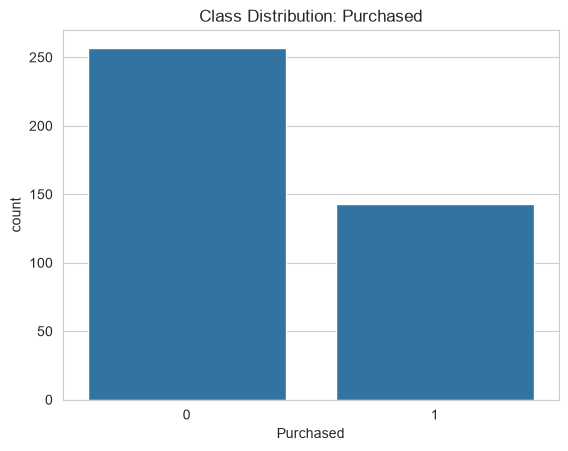

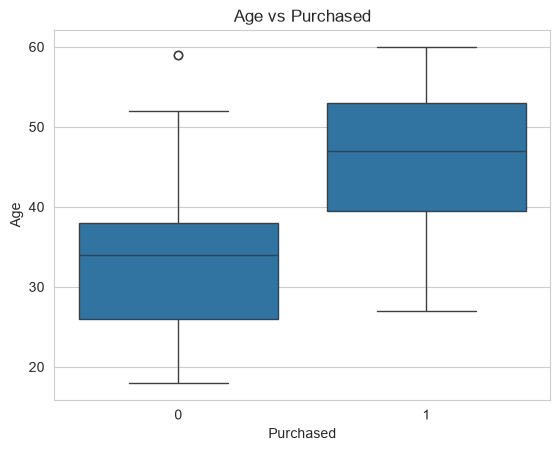

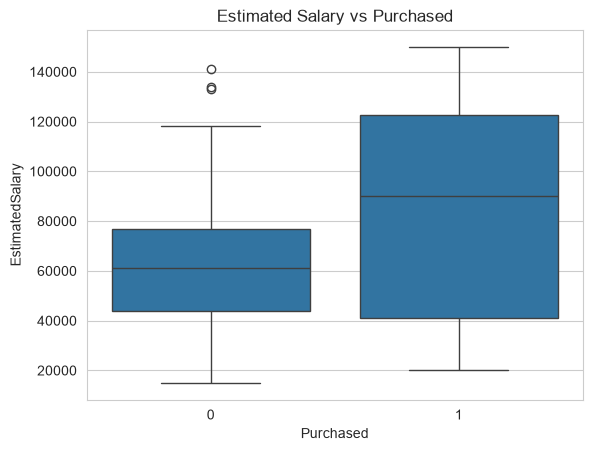

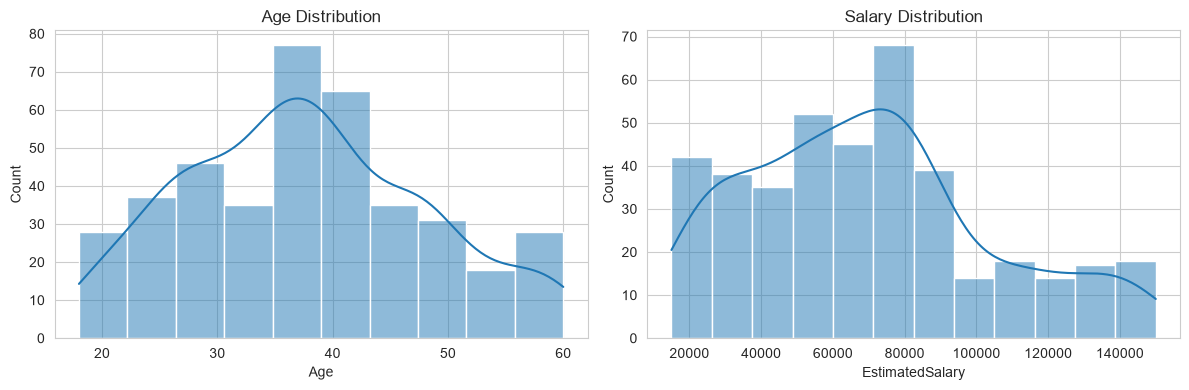

In [30]:
# Class distribution
sns.countplot(x="Purchased", data=df)
plt.title("Class Distribution: Purchased")
plt.show()

# Age vs Purchased
sns.boxplot(x="Purchased", y="Age", data=df)
plt.title("Age vs Purchased")
plt.show()

# Salary vs Purchased
sns.boxplot(x="Purchased", y="EstimatedSalary", data=df)
plt.title("Estimated Salary vs Purchased")
plt.show()

# Distributions
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df["Age"], kde=True, ax=ax[0]).set_title("Age Distribution")
sns.histplot(df["EstimatedSalary"], kde=True, ax=ax[1]).set_title("Salary Distribution")
plt.tight_layout()
plt.show()

In [31]:
# Check again explicitly
print("Missing:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print("Dtypes:\n", df.dtypes)

Missing:
 User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
Duplicates: 0
Dtypes:
 User ID             int64
Gender             object
Age                 int64
EstimatedSalary     int64
Purchased           int64
dtype: object


In [32]:
# Features (inputs)
X = df[["Age", "EstimatedSalary"]]

# Target (what we predict)
y = df["Purchased"]

print(X.shape, y.shape)

(400, 2) (400,)


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% for testing
    random_state=42,     # reproducible split
    stratify=y           # preserve class ratio in both sets
)

In [34]:
scaler = StandardScaler()

# Fit ONLY on training data, then transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [35]:
logistic_model = LogisticRegression(random_state=42, max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

logistic_pred = logistic_model.predict(X_test_scaled)
logistic_proba = logistic_model.predict_proba(X_test_scaled)[:, 1]

In [36]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

In [37]:
forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)
forest_proba = forest_model.predict_proba(X_test)[:, 1]

In [38]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)
knn_proba = knn_model.predict_proba(X_test_scaled)[:, 1]

In [39]:
def evaluate(name, y_true, y_pred, y_proba=None):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    auc  = roc_auc_score(y_true, y_proba) if y_proba is not None else None
    return dict(Model=name, Accuracy=acc, Precision=prec, Recall=rec, F1=f1, ROC_AUC=auc)

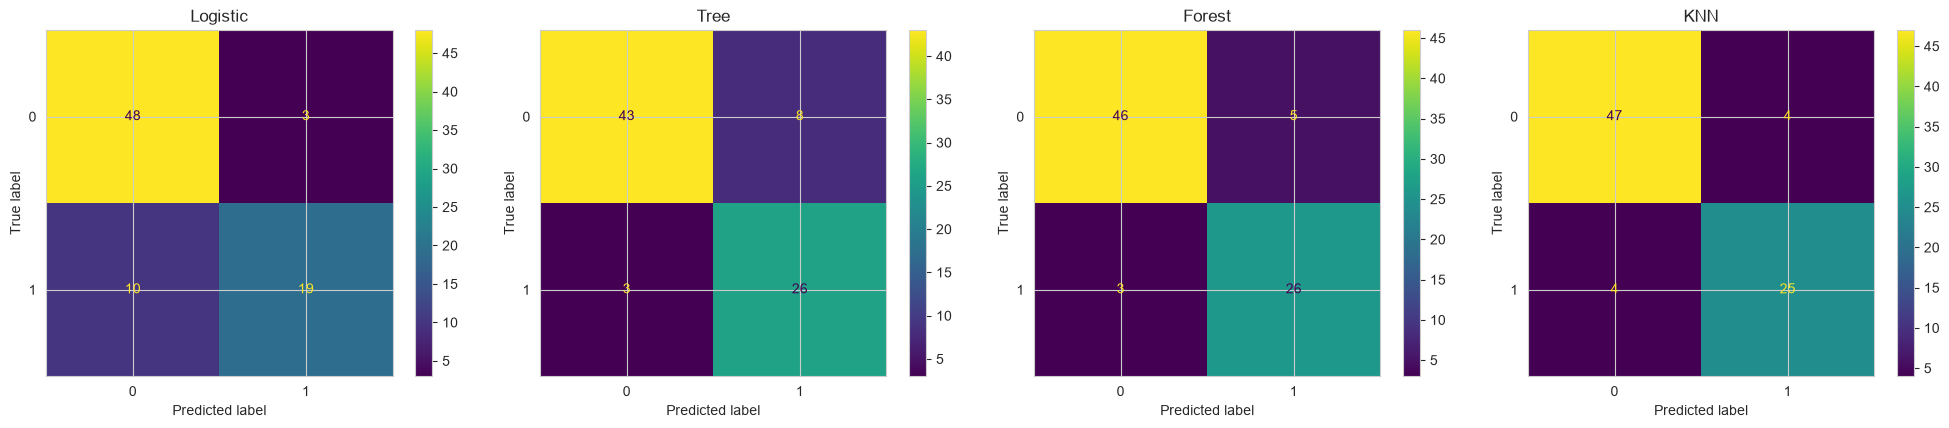

In [40]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, pred) in zip(axes, [
    ("Logistic", logistic_pred),
    ("Tree", tree_pred),
    ("Forest", forest_pred),
    ("KNN", knn_pred)
]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [41]:
for name, pred in [("Logistic", logistic_pred), ("Tree", tree_pred),
                   ("Forest", forest_pred), ("KNN", knn_pred)]:
    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred))


===== Logistic =====
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        51
           1       0.86      0.66      0.75        29

    accuracy                           0.84        80
   macro avg       0.85      0.80      0.81        80
weighted avg       0.84      0.84      0.83        80


===== Tree =====
              precision    recall  f1-score   support

           0       0.93      0.84      0.89        51
           1       0.76      0.90      0.83        29

    accuracy                           0.86        80
   macro avg       0.85      0.87      0.86        80
weighted avg       0.87      0.86      0.86        80


===== Forest =====
              precision    recall  f1-score   support

           0       0.94      0.90      0.92        51
           1       0.84      0.90      0.87        29

    accuracy                           0.90        80
   macro avg       0.89      0.90      0.89        80
weighted avg  

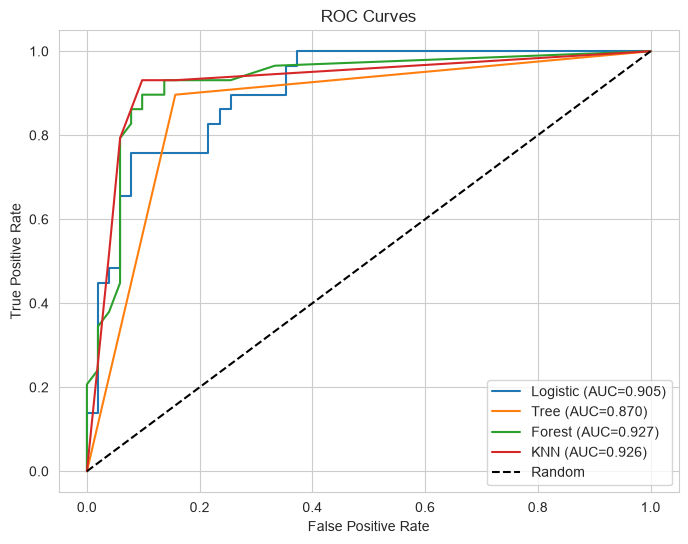

In [42]:
plt.figure(figsize=(8,6))

for name, proba in [
    ("Logistic", logistic_proba),
    ("Tree", tree_model.predict_proba(X_test)[:,1]),
    ("Forest", forest_proba),
    ("KNN", knn_proba),
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0,1],[0,1],'k--', label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

In [43]:
results = []
for name, pred, proba in [
    ("Logistic", logistic_pred, logistic_proba),
    ("Decision Tree", tree_pred, tree_model.predict_proba(X_test)[:,1]),
    ("Random Forest", forest_pred, forest_proba),
    ("KNN", knn_pred, knn_proba),
]:
    r = evaluate(name, y_test, pred, proba)
    results.append(r)

comparison = pd.DataFrame(results).set_index("Model").round(4)
comparison

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic,0.8375,0.8636,0.6552,0.7451,0.9053
Decision Tree,0.8625,0.7647,0.8966,0.8254,0.8698
Random Forest,0.9000,0.8387,0.8966,0.8667,0.9266
KNN,0.9000,0.8621,0.8621,0.8621,0.9256


In [44]:
train_scores = {
    "Logistic": logistic_model.score(X_train_scaled, y_train),
    "Decision Tree": tree_model.score(X_train, y_train),
    "Random Forest": forest_model.score(X_train, y_train),
    "KNN": knn_model.score(X_train_scaled, y_train),
}
test_scores = {
    "Logistic": logistic_model.score(X_test_scaled, y_test),
    "Decision Tree": tree_model.score(X_test, y_test),
    "Random Forest": forest_model.score(X_test, y_test),
    "KNN": knn_model.score(X_test_scaled, y_test),
}

overfit_df = pd.DataFrame({
    "Train Acc": train_scores,
    "Test Acc": test_scores
})
overfit_df["Gap"] = overfit_df["Train Acc"] - overfit_df["Test Acc"]
overfit_df.round(4)

,Train Acc,Test Acc,Gap
Logistic,0.8469,0.8375,0.0094
Decision Tree,0.9938,0.8625,0.1312
Random Forest,0.9938,0.9000,0.0938
KNN,0.9156,0.9000,0.0156


In [45]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
for name, model, X_data in [
    ("Logistic", LogisticRegression(max_iter=1000, random_state=42), X_train_scaled),
    ("Decision Tree", DecisionTreeClassifier(random_state=42), X_train),
    ("Random Forest", RandomForestClassifier(n_estimators=100, random_state=42), X_train),
    ("KNN", KNeighborsClassifier(n_neighbors=5), X_train_scaled),
]:
    scores = cross_val_score(model, X_data, y_train, cv=cv, scoring="roc_auc")
    cv_results[name] = (scores.mean(), scores.std())

pd.DataFrame(cv_results, index=["Mean AUC", "Std"]).T.round(4)

,Mean AUC,Std
Logistic,0.9287,0.0197
Decision Tree,0.8498,0.0361
Random Forest,0.9497,0.0190
KNN,0.9391,0.0206


In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Logistic Regression
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    {"C":[0.01,0.1,1,10], "solver":["lbfgs","liblinear"]},
    cv=cv, scoring="roc_auc", n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

# Decision Tree
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth":[3,5,7,10,None],
     "min_samples_split":[2,5,10],
     "min_samples_leaf":[1,2,5]},
    cv=cv, scoring="roc_auc", n_jobs=-1
)
dt_grid.fit(X_train, y_train)

# Random Forest
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {"n_estimators":[100,200],
     "max_depth":[5,10,None],
     "min_samples_split":[2,5],
     "min_samples_leaf":[1,2]},
    cv=cv, scoring="roc_auc", n_jobs=-1
)
rf_grid.fit(X_train, y_train)

# KNN
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    {"n_neighbors":[3,5,7,9,11],
     "weights":["uniform","distance"],
     "metric":["euclidean","manhattan"]},
    cv=cv, scoring="roc_auc", n_jobs=-1
)
knn_grid.fit(X_train_scaled, y_train)

print("LR best:", lr_grid.best_params_, lr_grid.best_score_)
print("DT best:", dt_grid.best_params_, dt_grid.best_score_)
print("RF best:", rf_grid.best_params_, rf_grid.best_score_)
print("KNN best:", knn_grid.best_params_, knn_grid.best_score_)

LR best: {'C': 10, 'solver': 'lbfgs'} 0.9289368461160613
DT best: {'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2} 0.9486670981898978
RF best: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100} 0.9614098873907994
KNN best: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'uniform'} 0.9584166540423167


In [47]:
tuned_models = {
    "LR Tuned": (lr_grid.best_estimator_, X_test_scaled),
    "DT Tuned": (dt_grid.best_estimator_, X_test),
    "RF Tuned": (rf_grid.best_estimator_, X_test),
    "KNN Tuned": (knn_grid.best_estimator_, X_test_scaled),
}

final = []
for name, (model, X_te) in tuned_models.items():
    pred  = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    final.append(evaluate(name, y_test, pred, proba))

pd.DataFrame(final).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
LR Tuned,0.8375,0.8636,0.6552,0.7451,0.9053
DT Tuned,0.8875,0.8125,0.8966,0.8525,0.9243
RF Tuned,0.9000,0.8387,0.8966,0.8667,0.9439
KNN Tuned,0.9125,0.8667,0.8966,0.8814,0.9449


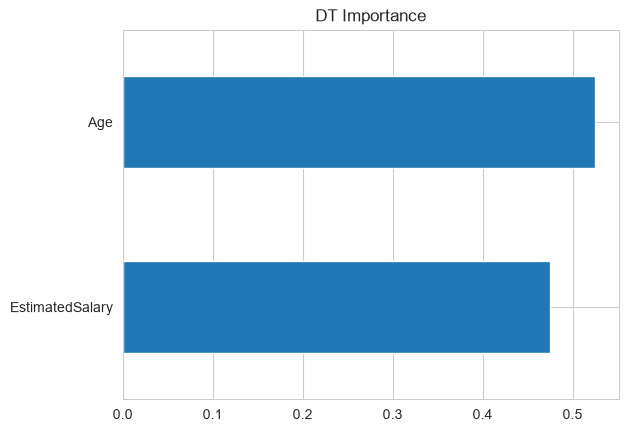

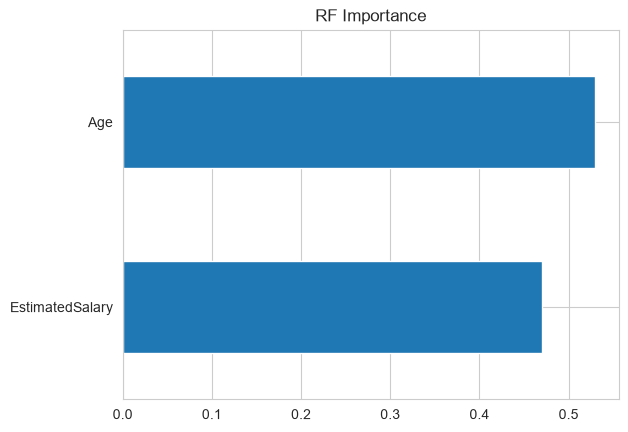

Age                2.366834
EstimatedSalary    1.347057
dtype: float64


In [48]:
# Decision Tree
pd.Series(dt_grid.best_estimator_.feature_importances_,
          index=X.columns).sort_values().plot(kind="barh", title="DT Importance")
plt.show()

# Random Forest
pd.Series(rf_grid.best_estimator_.feature_importances_,
          index=X.columns).sort_values().plot(kind="barh", title="RF Importance")
plt.show()

# Logistic Regression coefficients
coefs = pd.Series(lr_grid.best_estimator_.coef_[0], index=X.columns)
print(coefs)

In [49]:
def predict_customer(age, salary, model=rf_grid.best_estimator_, use_scaled=False):
    """
    Predict whether a customer will purchase.

    Parameters
    ----------
    age : int/float
    salary : int/float
    model : trained sklearn model (default = tuned Random Forest)
    use_scaled : bool
        True if the model expects scaled inputs (Logistic Regression, KNN)
        False for tree-based models (Decision Tree, Random Forest)

    Returns
    -------
    (prediction, probability_of_purchase)
        prediction : 0 or 1
        probability_of_purchase : float in [0, 1]
    """
    # 1. Build the input with the SAME column names used during training
    new_data = pd.DataFrame({"Age": [age], "EstimatedSalary": [salary]})

    # 2. Apply the same scaler if the model needs it
    if use_scaled:
        new_data = scaler.transform(new_data)   # transform only, never fit again

    # 3. Get probability of class 1 (purchase)
    proba = model.predict_proba(new_data)[0, 1]

    # 4. Threshold at 0.5 for a hard label
    pred = int(proba >= 0.5)

    return pred, proba


# --- Example usage (Random Forest = no scaling) ---
pred, proba = predict_customer(age=30, salary=60000)
print(f"Prediction: {'Will buy' if pred == 1 else 'Will not buy'}")
print(f"Probability of purchase: {proba*100:.2f}%")

# --- Example usage (Logistic Regression = scaled) ---
pred_lr, proba_lr = predict_customer(
    age=30, salary=60000,
    model=lr_grid.best_estimator_,   # ONE underscore
    use_scaled=True
)
print(f"\n[LR] Prediction: {'Will buy' if pred_lr == 1 else 'Will not buy'}")
print(f"[LR] Probability of purchase: {proba_lr*100:.2f}%")

Prediction: Will not buy
Probability of purchase: 1.68%

[LR] Prediction: Will not buy
[LR] Probability of purchase: 3.96%


In [50]:
import os
import joblib

# Make sure the folder exists no matter where the notebook is
MODELS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "models"))
os.makedirs(MODELS_DIR, exist_ok=True)
print("Saving into:", MODELS_DIR)

# Pick your final model — change this one line if you used LR or KNN
final_model = rf_grid.best_estimator_   # Random Forest (no scaling needed)
model_needs_scaling = False              # True for LR or KNN

joblib.dump(final_model, os.path.join(MODELS_DIR, "best_model.pkl"))
joblib.dump(scaler,      os.path.join(MODELS_DIR, "scaler.pkl"))
joblib.dump({"needs_scaling": model_needs_scaling},
            os.path.join(MODELS_DIR, "meta.pkl"))

# ---- Verify immediately ----
for fname in ["best_model.pkl", "scaler.pkl", "meta.pkl"]:
    p = os.path.join(MODELS_DIR, fname)
    print(fname, "->", os.path.getsize(p), "bytes")

# ---- Reload to prove it's valid ----
loaded = joblib.load(os.path.join(MODELS_DIR, "best_model.pkl"))
print("Reloaded OK:", type(loaded).__name__)

Saving into: c:\Users\sajiy\OneDrive\Desktop\New folcustomer-purchase-predictionder\models
best_model.pkl -> 300265 bytes
scaler.pkl -> 903 bytes
meta.pkl -> 32 bytes
Reloaded OK: RandomForestClassifier


In [51]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

def safe_dump(obj, path):
    """Write to .tmp first, then rename — prevents half-written files."""
    tmp = path + ".tmp"
    joblib.dump(obj, tmp, compress=3)
    os.replace(tmp, path)
    size = os.path.getsize(path)
    print(f"✅ {os.path.basename(path):35s} {size:>10,} bytes")

# ---- Save every tuned model ----
safe_dump(lr_grid.best_estimator_,  "../models/logistic_model.pkl")
safe_dump(dt_grid.best_estimator_,  "../models/decision_tree_model.pkl")
safe_dump(rf_grid.best_estimator_,  "../models/random_forest_model.pkl")
safe_dump(knn_grid.best_estimator_, "../models/knn_model.pkl")
safe_dump(scaler,                    "../models/scaler.pkl")

# ---- Verify immediately ----
print("\n--- Verification ---")
for f in ["logistic_model", "decision_tree_model",
          "random_forest_model", "knn_model", "scaler"]:
    p = f"../models/{f}.pkl"
    try:
        obj = joblib.load(p)
        print(f"✅ {f}.pkl → {type(obj).__name__}")
    except Exception as e:
        print(f"❌ {f}.pkl → {type(e).__name__}: {e}")

✅ logistic_model.pkl                         564 bytes
✅ decision_tree_model.pkl                  1,279 bytes
✅ random_forest_model.pkl                 60,021 bytes
✅ knn_model.pkl                            4,339 bytes
✅ scaler.pkl                                 552 bytes

--- Verification ---
✅ logistic_model.pkl → LogisticRegression
✅ decision_tree_model.pkl → DecisionTreeClassifier
✅ random_forest_model.pkl → RandomForestClassifier
✅ knn_model.pkl → KNeighborsClassifier
✅ scaler.pkl → StandardScaler
